In [19]:
import numpy as np
import pandas as pd

from sklearn.metrics import root_mean_squared_error 
from tqdm import tqdm

import matplotlib.pyplot as plt

import os
os.chdir(r'E:\Backup Files Abhinav_Satyam\Practical Machine Learning\Sanjay Sir Git Repo\Datasets')
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

from statsmodels.tsa.api import Holt , SimpleExpSmoothing ,ExponentialSmoothing 

In [20]:
BUNDESBANK = pd.read_csv('BUNDESBANK-BBK01_WT5511.csv')
BUNDESBANK

,Date,Value
0,30-04-1968,39.10
1,31-05-1968,42.00
2,30-06-1968,40.95
3,31-07-1968,38.90
4,31-08-1968,39.85
...,...,...
572,31-12-2015,1062.25
573,31-01-2016,1112.90
574,29-02-2016,1234.15
575,31-03-2016,1233.60


In [21]:
y = BUNDESBANK['Value']
y_train , y_test  = y.iloc[:-12] , y.iloc[-12:]

In [22]:
y_train.shape, y_test.shape

((565,), (12,))

In [8]:
# Simple Exponential
alpha   = np.linspace(0.01,0.99,20)  
scores = []

for a in alpha:
    ses = SimpleExpSmoothing(y_train)
    
    fit1 = ses.fit(smoothing_level=a)
    fcast1 = fit1.forecast(len(y_test))

    
    scores.append([a , root_mean_squared_error(y_test , fcast1)])
    
df_scores = pd.DataFrame(scores, columns = ['alpha'  ,'score'])
df_scores.sort_values('score')

E:\Installed_Applications\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)
E:\Installed_Applications\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)
E:\Installed_Applications\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)
E:\Installed_Applications\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimized=False to suppress this warning
  return func(*args, **kwargs)
E:\Installed_Applications\Lib\site-packages\pandas\util\_decorators.py:213: EstimationWarning: Model has no free parameters to estimate. Set optimiz

,alpha,score
13,0.680526,81.986063
14,0.732105,82.042383
12,0.628947,82.067648
15,0.783684,82.244935
11,0.577368,82.279767
16,0.835263,82.598949
10,0.525789,82.622645
17,0.886842,83.104191
9,0.474211,83.114374
18,0.938421,83.753606


In [7]:
# Exponential Smoothing
alpha , beta  = np.linspace(0.01,0.99,20) , np.linspace(0.01 , 0.99,20) 

scores = []

for a in tqdm(alpha):
    for b in beta: 
        for e in [True,False]:
            holt = Holt(y_train , exponential=e) 
            
            fit1 = holt.fit(smoothing_level=a , smoothing_trend = b, optimized=False)  
            fcast1 = fit1.forecast(len(y_test)) 
               

            scores.append([a,b, e,root_mean_squared_error(y_test , fcast1)])

df_scores = pd.DataFrame(scores, columns = ['alpha' ,'beta','exponential','score'])
df_scores.sort_values('score')

100%|██████████| 20/20 [00:09<00:00,  2.20it/s]


,alpha,beta,exponential,score
1,0.010000,0.010000,False,6.094909e+01
89,0.113158,0.216316,False,6.201787e+01
156,0.164737,0.938421,True,6.220728e+01
157,0.164737,0.938421,False,6.379900e+01
88,0.113158,0.216316,True,6.430678e+01
...,...,...,...,...
5,0.010000,0.113158,False,8.952058e+02
6,0.010000,0.164737,True,1.471932e+03
4,0.010000,0.113158,True,2.020474e+03
2,0.010000,0.061579,True,2.077322e+03


In [12]:
alpha , beta , gamma = np.linspace(0.01,0.99,20) , np.linspace(0.01 , 0.99,20) , np.linspace(0.01 , 0.99,20)
seasoality = ['add','mul']
scores = []

for a in tqdm(alpha):
    for b in beta:
        for g in gamma:
            for s in seasoality:
             
                hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal=s)   
                
                fit1 = hw_add.fit(smoothing_level=a , smoothing_trend=b, smoothing_seasonal=g,optimized=False,)  
                fcast1 = fit1.forecast(len(y_test)) 
                   
    
                scores.append([a,b,g,s, root_mean_squared_error(y_test , fcast1)])

df_scores = pd.DataFrame(scores, columns = ['alpha' ,'beta', 'gamma','season','score'])
df_scores.sort_values('score')

100%|██████████| 20/20 [04:13<00:00, 12.70s/it]


,alpha,beta,gamma,season,score
13623,0.886842,0.010000,0.577368,mul,3.935725e+01
14425,0.938421,0.010000,0.628947,mul,3.995490e+01
15225,0.990000,0.010000,0.628947,mul,4.008540e+01
14423,0.938421,0.010000,0.577368,mul,4.068259e+01
12821,0.835263,0.010000,0.525789,mul,4.577882e+01
...,...,...,...,...,...
15994,0.990000,0.990000,0.886842,add,4.505029e+16
15918,0.990000,0.886842,0.990000,add,5.313814e+16
15958,0.990000,0.938421,0.990000,add,3.012937e+17
15996,0.990000,0.990000,0.938421,add,6.965758e+17


In [ ]:
alpha, beta = np.linspace(0.01, 0.99, 20), np.linspace(0.01, 0.99, 20)
gamma = np.linspace(0.01, 0.99, 20)
scores = []
seasonality = ['add','mul']
for a in tqdm(alpha):
  for b in beta:
    for g in gamma:
        for s in seasonality:
            hw_add = ExponentialSmoothing(
            y_train, 
            seasonal_periods=12, 
            trend='add', 
            seasonal=s
           )
            fit1 = hw_add.fit(smoothing_level=a, smoothing_trend=b, smoothing_seasonal=g)
            fcast1 = fit1.forecast(len(y_test)) 
            rms = np.round(root_mean_squared_error(y_test, fcast1), 2)
            scores.append([a, b, g,s, rms])
df_scores = pd.DataFrame(scores, columns=['alpha', 'beta', 'gamma','seasonal', 'score'])
df_scores.sort_values('score')    

 30%|███       | 6/20 [05:20<12:19, 52.85s/it]

RMSE = 39.36


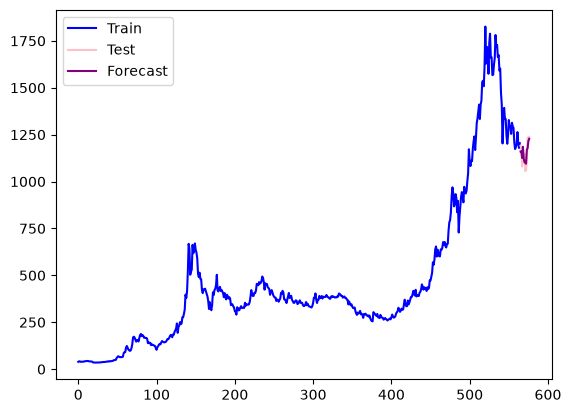

In [15]:
alpha = 0.112


hw_add = ExponentialSmoothing(y_train , seasonal_periods=12 , trend = 'add' , seasonal='mul')   
                
fit1 = hw_add.fit(smoothing_level=0.886842 , smoothing_trend=0.010000, smoothing_seasonal=0.577368,optimized=False)  
fcast1 = fit1.forecast(len(y_test)) 


y_train.plot(color = 'blue', label = 'Train')
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')

rms = np.round(root_mean_squared_error(y_test , fcast1),2)
print(f'RMSE = {rms}')
plt.legend(loc='best')


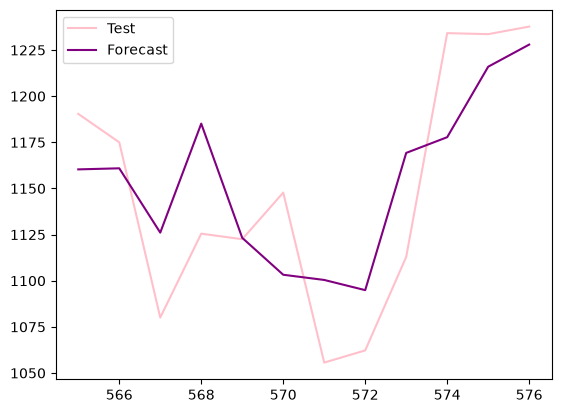

In [16]:
y_test.plot(color = 'pink', label = 'Test')
fcast1.plot(color = 'purple', label = 'Forecast')
plt.legend(loc='best')
